# Домашнее задание 5. Классификация

В этот раз вам нужно поработать с задачей sentiment analysis на примере отзывов на фильмы.

Датасет доступен [здесь](https://www.kaggle.com/datasets/lakshmi25npathi/imdb-dataset-of-50k-movie-reviews). Посмотрите, как устроены данные, как распределены оценки.


## Задание 1 (1 балл)

Нарисуйте два вордклауда: для позитивных и негативных. Постарайтесь сделать их информативными: например, не отображайте "общеанглийские" стоп-слова. Возможно, какие-то еще слова оказались частотными и для позитивных, и для негативных, и их тоже можно убрать?

In [5]:
import matplotlib.pyplot as plt
import nltk
nltk.download("wordnet")
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import wordpunct_tokenize
from wordcloud import WordCloud
from nltk.corpus import stopwords

[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


In [6]:
import pandas as pd
# i want to delete english stopwords and some extra "universal" movie words
# for some reason nlrk lemmatizer lemmatizes "was" as "wa" and "has" as "ha", so i had to delete them manually
stops = set.union(set(stopwords.words('english')), set(["movie", "character", "plot", "actor", "actress", "twist", "ending", "br", "one", "time", "film", "even", "story", "show", "make", "film", "wa", "ha", "b", "go", "see"]))

In [7]:
morph = WordNetLemmatizer()

In [8]:
def lemmatize(x):  # also it would be nice not to double the same lexeme because of different wordforms, so i used this function from the seminar
    if type(x) != str:
        return ""
    text = wordpunct_tokenize(x)
    result = []
    for word in text:
        if word.isalpha():  # we're checking id the word really is a word
            nf = morph.lemmatize(word)
            if nf not in stops:  # and deleting stopwords
                result.append(nf)
    return " ".join(result)

In [9]:
df = pd.read_csv("reviews.csv")

In [10]:
# making a solid text from the data in the dataset
textpos = " ".join(df.loc[df["sentiment"] == "positive", "review"].apply(lemmatize).values)
textneg = " ".join(df.loc[df["sentiment"] == "negative", "review"].apply(lemmatize).values)

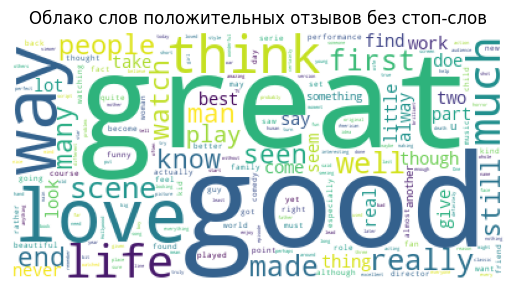

In [141]:
# now it is just about making the wordclouds
poscloud = WordCloud(background_color ='white').generate(textpos)
negcloud = WordCloud(background_color ='white').generate(textneg)

plt.figure() 
plt.imshow(poscloud)
plt.axis("off") 
plt.title('Облако слов положительных отзывов без стоп-слов')
plt.show()

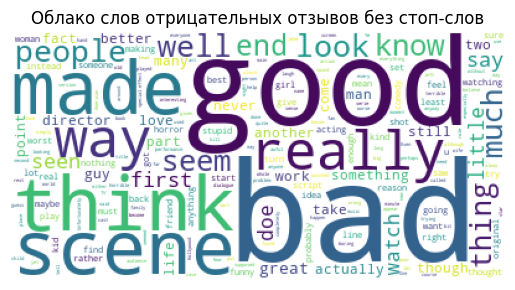

In [142]:
plt.figure() 
plt.imshow(negcloud)
plt.axis("off")
plt.title('Облако слов отрицательных отзывов без стоп-слов')
plt.show()

## Задание 2 (1 балл)
Разбейте данные на обучающую и тестовую выборки и векторизуйте каким-либо способом, про который мы говорили на семинаре.


In [12]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer

In [109]:
# dividing our data into to parts_ one for the vectorizer to fit onto, and another -- to test it
X = df["review"]
y = df["sentiment"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# vectorizing. i've chosen CountVectorizer for the first try
vectorizer = CountVectorizer()
X_train_count = vectorizer.fit_transform(X_train)
X_test_count = vectorizer.transform(X_test)

## Задание 3 (1 балл)

Обучите любой классификатор на обучающей выборке и замерьте качество на тестовой выборке. Вспомните, что такое accuracy, precision (точность), recall (полнота). Напишите функции, сравнивающие истинные метки с предсказанными и считающие метрики. Проверьте, что результат вашей реализации совпадает с метриками из sklearn.

In [120]:
# honestly kNN-classifier is the one the best i've understood so far (i hope), also the data seems more or less suitable so let's try that one
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5)

# let's teach the classifier
knn.fit(X_train_count, y_train)

# and then make it predict stuff based on the training sample
y_knn_count = knn.predict(X_test_count)

In [121]:
# so now we have predictions. let's check the quality of it with built-in methods

from sklearn.metrics import accuracy_score, recall_score, precision_score
first_accuracy = accuracy_score(y_test, y_knn_count)
first_recall = recall_score(y_test, y_knn_count, pos_label = "positive")
first_precision = precision_score(y_test, y_knn_count, pos_label = "positive")

In [122]:
y_true = y_test.reset_index(drop="true")  # i want to compare right answers and predictions as normal arrays so i had to have their ids matched

In [123]:
# and we can also make our own functions for counting the same metrics
def my_accuracy(y_test, y_knn_count):
    rightpred = [x for i in range(len(y_knn_count) - 1) if y_knn_count[i] == y_test[i]]
    return(len(rightpred)/len(y_knn_pred))

In [124]:
def my_recall(y_test, y_knn_count):
    tp = [x for i, x in enumerate(y_knn_count) if x == y_test[i] and x == "positive"]  # array of true predictions of positive (tp)
    tpplusfn = [x for x in y_test if x == "positive"]  # array of all predictions that were supposed to be positive ideally (tp + fn)
    return(len(tp)/len(tpplusfn))

In [125]:
def my_precision(y_test, y_knn_count):
    tp = [x for i, x in enumerate(y_knn_count) if x == y_test[i] and x == "positive"]  # array of true predictions of positive (tp)
    tpplusfp = [x for x in y_knn_count if x == "positive"]  # array of all predictions of positive (tp + fp)
    return(len(tp)/len(tpplusfp))

In [126]:
# let's compare the results!
print(f"Accuracy by in-built metod: {first_accuracy}")
print(f"Recall by in-built metod: {first_recall}")
print(f"Precision by in-built metod: {first_precision}")
print(f"Accuracy by hand: {my_accuracy(y_true, y_knn_count)}")
print(f"Recall by hand: {my_recall(y_true, y_knn_count)}")
print(f"Precision by hand: {my_precision(y_true, y_knn_count)}")

Accuracy by in-built metod: 0.6426
Recall by in-built metod: 0.7160150823576107
Precision by in-built metod: 0.6273691531907495
Accuracy by hand: 0.6426
Recall by hand: 0.7160150823576107
Precision by hand: 0.6273691531907495


*Our answers do match! :) so our functions work as well*

## Задание 4 (1 балл)
Объясните **своими** (не коллеги, поста в интернете или chatGPT) словами, как работают выбранные векторизатор и классификатор и что означает каждая из метрик: accuracy, recall, precision

**CountVectorizer** создаёт список всех уникальных токенов из корпуса и строит матрицу, в которой строки = документы, столбцы = все токены из корпуса, а в каждой ячейке - число вхождений данного токена в данном документе. **Классификатор kNN (Nearest Neghbors)** относит каждый элемент данных, требующих классификации, к классу, к которому относится наибольшее число его ближайших соседей (из тренировочной выборки, про которых уже известно, к каким классам они относятся). 
**Метрики**:
* Accuracy -- метрика, определяющая, насколько точны предсказания модели overall: отношение количества верных ответов модели к количеству всех ответов. 
* Recall -- метрика, определяющая, насколько хорошо модель способна назвать элементы "целевого" класса таковыми, (в нашем случае деление бинарное, так что в качестве "нужных" были случайным образом выбраны положительные отзывы) класса, не засунув их в другие классы: отношение true positive количества предсказаний (верных отнесений элементов к целевым классам) к сумме true positive предсказаний и false negative (неверных отнесений элементов к  нецелевым классам) предсказаний.
* Precision -- метрика, определяющая, насколько хорошо модель способна назвать только элементы "целевого" класса таковыми, не присовокупив к ним элементы нецелевых: отношение true positive предсказаний к сумме true positive и false positive (неверных отнесений элементов к целевым классам) предсказаний.

## Задание 5 (1 балл)

Используйте другой метод векторизации и тот же классификатор. Замерьте качество. Как оно изменилось?

In [127]:
# попробуем использовать метрику тф-идф
from sklearn.feature_extraction.text import TfidfVectorizer

In [155]:
# i've understood so we don't have to change our train and test samples, because they are still as random as they'll ever be.
# it's just the results of vectorization will change with every new vectorizer

In [128]:
another_vectorizer = TfidfVectorizer()

# we have to train and test new vectorizer the same way
X_train_tfidf = another_vectorizer.fit_transform(X_train)
X_test_tfidf = another_vectorizer.transform(X_test)

In [129]:
# so let's test kNN on Tfidf vectorization results

tfidfknn = KNeighborsClassifier(n_neighbors=5)  # new classifier so we don't re-teach the first one
tfidfknn.fit(X_train_tfidf, y_train)
y_knn_tfidf = tfidfknn.predict(X_test_tfidf)

# and check how well this's turned out
tfidfaccuracy = accuracy_score(y_true, y_knn_tfidf)
tfidfrecall = recall_score(y_test, y_knn_tfidf, pos_label = "positive")
tfidfprecision = precision_score(y_test, y_knn_tfidf, pos_label = "positive")
print(f"Accuracy: {tfidfaccuracy}")
print(f"Recall: {tfidfrecall}")
print(f"Precision: {tfidfprecision}")

Accuracy: 0.769
Recall: 0.8076999404643779
Precision: 0.7521715024949177


## Задание 6 (1 балл)

Для обоих векторизаторов попробуйте использовать другой классификатор. Опишите своими словами, как работает новый классификатор.

Как изменилось качество с другой моделью?

In [133]:
# let's try logistic regression: i don't think that DecisionTree will work well with this kind of data -- there isn't enough parameters
from sklearn.linear_model import LogisticRegression

In [134]:
# at first -- with CountVectorizer-ed data
countlogreg = LogisticRegression()
countlogreg.fit(X_train_count, y_train)  # we still can use old vectorization results: they haven't changed
y_lr_count = countlogreg.predict(X_test_count)

C:\Users\user\AppData\Local\Programs\Python\Python311\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [135]:
# and then -- with TfidfVectorizer-ed data
tfidflogreg = LogisticRegression()
tfidflogreg.fit(X_train_tfidf, y_train)
y_lr_tfidf = tfidflogreg.predict(X_test_tfidf)

In [136]:
# and let's compare metrics!
acccnt = accuracy_score(y_lr_count, y_test)
acctf = accuracy_score(y_lr_tfidf, y_test)
reccnt = recall_score(y_lr_count, y_test, pos_label = "positive")
rectf = recall_score(y_lr_tfidf, y_test, pos_label = "positive")
precnt = precision_score(y_lr_count, y_test, pos_label = "positive")
pretf = precision_score(y_lr_tfidf, y_test, pos_label = "positive")
print(f"Accuracy is {acccnt} for CountVectorizer and {acctf} for TfidfVectorizer")
print(f"Recall is {reccnt} for CountVectorizer and {rectf} for TfidfVectorizer")
print(f"Accuracy is {precnt} for CountVectorizer and {pretf} for TfidfVectorizer")

Accuracy is 0.893 for CountVectorizer and 0.8999 for TfidfVectorizer
Recall is 0.8882801800039132 for CountVectorizer and 0.8914307871267934 for TfidfVectorizer
Accuracy is 0.9009724151617384 for CountVectorizer and 0.9124826354435404 for TfidfVectorizer


## Задание 7 (1 балл)

Получилось 4 набора результатов. Сравните их. Что вы можете сказать? Как меняется качество?

Можно отметить, что Tf-Idf заведомо качественнее векторизует отзывы: любой классификатор лучше работает на векторизированных через TfidfVectorizer данных (все три метрики при его использовании выше, чем при CountVectorizer). Наиболее высокие метрики наблюдаются при использовании TfidfVectorizer и логистической регрессии. (Кстати, и здесь, и дальше метрики одинаково увеличиваются и уменьшаются при манипуляциях с веркторизаторами и классификаторами; нет такого, что одна растёт, а другая убывает). В принципе это, наверное, логично, поскольку метод ближайших соседей работает лучше всего тогда, когда классы разделены довольно отчётливо: в случае же отзывов мы даже в вордклаудах можем увидеть, что положительные и отрицательные отзовы не будут настолько чётко разнесены в векторном пространстве, у них будет "серая" зона. Возможно, поэтому логистическая регрессия оказалась более эффективна.

## Задание 8 (3 балла)

## Задание 8.1 (2 балла из 3)

У векторизаторов и классификаторов есть множество параметров. Переключать их руками, перезапускать ячейки и записывать результаты — не очень удобно. Лучше это автоматизировать:
1. Выберите несколько параметров и возможных значений. Напишите своими словами, за что отвечают эти значения.
2. Напишите перебор каждого значения каждого параметра, чтобы проверить все возможные сочетания
3. Обучайте векторизатор и классификатор с данным набором параметров на тренировочной выборке, затем замеряйте качество на тестовой. Если получается лучше, чем было — сохраняйте результат и параметры, с которыми он получился. (По какой метрике или набору метрик считать параметры "лучше", решите самостоятельно)

В итоге вы получите значения параметров для векторизатора и классификатора, которые ведут к наибольшему качеству. Выведите параметры и соответствующие метрики.

Можно посмотреть, сможем ли мы улучшить качество классификатора kNN, изменяя количество соседей, на классы которых опирается определение каждого элемента. 
В качестве метрики я бы взяла accuracy: у нас бинарная классификация, нет такого, что мы выделяем какой-то один класс из всех остальных и смотрим именно на него, так что показательной будет общая точность ответов. 
О векторизации: [у векторизатора TfIdf есть три численных параметра (из документации)](https://scikit-learn.org/stable/modules/generated/sklearn.feature_extraction.text.TfidfVectorizer.html)  -- **max_df** (устанавливающий верхний порог частоты терма во всём корпусе), **min_df** (устанавливающий нижний порог частоты терма во всём корпусе) и **max_features** (ранжирующий все термы по tf и выбирающий только определённое число самых верхних в рейтинге). При этом первые два из этих параметров могут в том числе принимать на вход дробь от 0 до 1, и тогда порог [будет определён в процентах от общего числа документов (более ясно здесь)](https://stackoverflow.com/questions/27697766/understanding-min-df-and-max-df-in-scikit-countvectorizer), в которых встречается терм, но третий принимает только абсолютную величину. Мне кажется, по абсолютной величине перебор будет сложнее, а результаты менее анализируемы: max_features полезно применять, если более редкие в пределах одного отзыва слова будут что-то говорить об окраске отзыва, но в нашем случае мне кажется, что min_df в нашем случае сработает не хуже, так что я склоняюсь к тому, чтобы перебирать разные значения max_ и min_df.

In [147]:
# at first let's understand, which values are the chosen parameters going to receive
# so each element's class is going to be determined based on the most frequent class amongst its 5, 7, etc. neighbours
knn_vals = [5, 7, 9, 11]
# only those terms will be taken in account that exist in more than 10%, 20% or 30% of reviews (getting rid of each review's specific lexicon
min_vec_vals = [0.1, 0.2, 0.3]  
# only those terms will be taken in account that exist in less than 90%, 70% or 50% of reviews
max_vec_vals = [0.9, 0.7, 0.5]

best_answers = {
    "neigh": 0,
    "mindf": 0,
    "maxdf": 0,
    "accuracy": 0
} # we'll write the best answers here
    
for i in min_vec_vals:
    for j in max_vec_vals:
        veczer = TfidfVectorizer(max_df=j, min_df=i)
        X_train_ready = veczer.fit_transform(X_train)
        X_test_ready = veczer.transform(X_test)
        for x in knn_vals:
            classifier = KNeighborsClassifier(n_neighbors=x)
            classifier.fit(X_train_ready, y_train)
            y_predicted = classifier.predict(X_test_ready)
            acc = accuracy_score(y_predicted, y_test)
            if acc > best_answers["accuracy"]:
                best_answers["accuracy"] = acc
                best_answers["neigh"] = x
                best_answers["mindf"] = i
                best_answers["maxdf"] = j   


In [151]:
a = best_answers["neigh"]
b = best_answers["mindf"]
c = best_answers["maxdf"]
d = best_answers["accuracy"]
print(f"The best number of closest neighbours is {a}, the best min_df is {b} and the best max_df is {c}.")
print(f"The accuracy score with these parameters is {d}")

The best number of closest neighbours is 11, the best min_df is 0.1 and the best max_df is 0.5.
The accuracy score with these parameters is 0.6972


Ответы даже логичны в большей степени! Логично, что чем больше соседей рассматривает классификатор, тем точнее будут предсказания (хотя по сравнению с логистической регрессией точность всё равно невысокая). Видимо, ограничение max_df позволяет избавиться от типичной лексики для конкретно этого вида документов (отзывов), которые затуманивают характер отзыва. А вот min_df напротив, выгоднее делать поменьше: видимо, редкая для корпуса лексика помогает разделять отзывы на положительные и отрицательные.

## Задание 8.2 (1 балл из 3)

Только что вы реализиовали **перебор параметров по сетке**. В sklearn есть его имплементация: [sklearn.model_selection.GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).

Объект класса `GridSearchCV` принимает классификатор (создаем объект, но не указываем никакие параметры) и сетку параметров. Дополнительно можно указать `scoring` из [списка](https://scikit-learn.org/stable/modules/model_evaluation.html#scoring-parameter). Если `scoring` не указано, то по умолчанию будет использоваться MSE для регрессии и accuracy для классификации.

После этого вызываем `fit` от данных, чтобы подобрать лучшие параметры. Обратите внимание: GridSearchCV автоматически разбивает на трейн и тест для поиска лучших параметров. Если быть точнее, то делает несколько разных случайных разбиений, а затем считает среднее качество на этих нескольких тестовых выборках для текущих параметров.

Попробуйте переписать ваш поиск по сетке на `GridSearchCV`. Получились ли у вас такие же результаты? Если нет — это нормально, но подумайте, почему они могут не совпадать.

In [162]:
from sklearn.model_selection import GridSearchCV
# okay, let's try the same, but with GridSearchCV
parametersmine = {
    "n_neighbors": [5, 7, 9, 11]
}
finclassifier = KNeighborsClassifier()
clfmine = GridSearchCV(
    estimator=finclassifier,  # our "empty" object
    param_grid=parametersmine,  # dict {param: values}
    scoring="accuracy"
)
# let's use the vectorized data from the TfIdf-vectorization in the 5-th punct
clfmine.fit(X_train_tfidf, y_train)

GridSearchCV(estimator=KNeighborsClassifier(),
             param_grid={'n_neighbors': [5, 7, 9, 11]}, scoring='accuracy')

In [163]:
# best parameters
clfmine.best_params_

{'n_neighbors': 11}

In [164]:
# best accuracy score
clfmine.best_score_

0.766175

In [167]:
# clf.predict вызывает predict от лучшей модели
y_predfin = clfmine.predict(X_test_tfidf)
accuracy_score(y_predfin, y_test)

0.7786

Довольно ожидаемо, что пункты 8.1 и 8.2 не совпадают: в первом был перебор по векторизации, а здесь нет. Вероятно, я была неправа, когда в переборе параметров векторизатора в пункте 8.1 не дала абсолютных значений мин_дф и макс_дф: кажется, с их дефолтными значениями accuracy получилась выше. Всё ещё лучше всего, когда соседей 11!